# Case Study 2 — Whole-scalp spectral analysis of resting-state EEG (R)

This is the **R implementation** of Case Study 2. It implements the
analysis described in Section 4.2 of the companion paper. The same
analysis is also available as
[Python code](../../../python/CaseStudy_2/CaseStudy_2.ipynb).

The research question is:

> *Does the spectral profile of resting-state EEG relate to global
> cognitive functioning, without restricting the analysis in advance to
> a specific frequency band or region?*

Where [Case Study 1](../../case1/code/CaseStudy_1.ipynb) reduces the EEG
signal to four theory-driven scalar features, this case study keeps the
**full power spectral density** (PSD, 1–40 Hz, every channel) and asks
broadly *where* — across the whole scalp and spectrum — resting EEG
power relates to global cognition (MoCA), motivated by a well-established
clinical observation: right-hemisphere stroke is frequently accompanied
by pathological EEG slowing (more delta/theta power over the affected
region) that tracks the severity of impairment (Finnigan & Van Putten,
2013).

## A note on the data

- The EEG spectra used here are **real, anonymised recordings**.
- The neuropsychological table (age, sex, CRIq, MoCA) is **synthetic**,
  as in Case Study 1.
- Because the two do not come from the same assessment, the `moca`
  column was deliberately linked to a real, montage-based property of
  each EEG recording — see the notice at the top of
  `data/generate_datasets.ipynb` for the full disclosure. **The
  resulting brain–behaviour association should not be read as a real
  clinical finding**; it exists so this case study has something real to
  recover.

## Pipeline

1. **Data Wrangling** — load & align, inspect, missing data, log-power
   distributions, covariate strategy
2. **Analysis** — descriptive stats, a Case-Study-1-style baseline model,
   mass-univariate partial correlation, cluster-based permutation
   (primary whole-spectrum test + a pre-registered secondary/confirmatory
   test)
3. **Export** — figures and tables (CSV + Excel)
4. **Strengths and limitations**

> The Python version uses `mne` for electrode positions, spatial
> adjacency, and topographic plots. R has no equivalent package, so
> this instead reads three small, plain-CSV files — channel
> positions, channel adjacency, and the scalp outline — pre-exported
> from the real montage by
> [`data/EEG/PSD/compute_montage_assets.ipynb`](../../../data/EEG/PSD/compute_montage_assets.ipynb).
> Everything downstream (the statistics, the cluster test, the topomap
> interpolation) is plain R.

## How this code is built

Like almost any real analysis, this notebook combines two things:

1. **Functions from established packages** - the
   [tidyverse](https://www.tidyverse.org/) (`readr`, `dplyr`, `tidyr`,
   `purrr`, `stringr`, `ggplot2`) to read, reshape and plot the data,
   `broom` to turn models into tables, `Matrix`, `MASS` and `igraph` for
   the linear algebra and graph steps, `patchwork` to combine plots,
   `openxlsx` for Excel export and `cli` for readable messages.
2. **A few custom functions** for what no package we use here covers: a
   reader for NumPy's `.npy` files, the cluster-based permutation test,
   and the topographic map. In Python, `numpy` reads `.npy` files and
   `mne` draws the topomaps (the cluster test is a short custom function
   there too); R has packages for parts of this as well (e.g.
   `reticulate`, `permuco`, `eegUtils`), but to keep the dependencies
   light we use small helpers instead. They live in the [`R/`](https://github.com/SanCamilloIRCCS-OndaLab/tutorial_EEG-NPSY/tree/main/r/case2/code/R) folder next to this notebook and
   are loaded in Setup, just as you would load a small package of your own
   - so the notebook itself reads as the analysis, step by step.

The custom functions are hidden by default, but they are not a black box:
wherever one is first used, a collapsed cell lets you print its source code
(or simply open the file in `R/`).

> ⚠️ **Caution** - the custom functions in `R/` (the `.npy` reader, the
> cluster-based permutation test and the topographic map) are minimal,
> didactic implementations, written only so this tutorial runs in R
> without extra dependencies. They are **not extensively tested**, and
> they are **not** a validated or published implementation of
> cluster-based permutation testing. For real analyses use established,
> peer-reviewed tools - MNE-Python, FieldTrip, or R packages such as
> `permuco` and `eegUtils`.

## 0. Setup

Load the packages we use throughout the analysis, then our own helper
functions from the `R/` folder.

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)  # readr, dplyr, tidyr, purrr, stringr, ggplot2, ...
  library(broom)      # model results as tidy tibbles
  library(patchwork)  # combine ggplot panels into one figure
  library(Matrix)     # sparse matrices, for channel/frequency adjacency (ships with R)
  library(cli)        # readable status messages
})
# MASS (pseudo-inverse), igraph (connected components) and openxlsx (Excel
# export) are only needed in one place each, so they are called as
# pkg::fun() instead of being attached.

theme_set(theme_minimal())

# Fixed number of decimals, for plot titles and labels
fmt <- function(x, digits = 1) formatC(x, format = "f", digits = digits)

# Our own helper functions, one file per topic in the R/ folder next to this
# notebook - loaded the way you would load a small package of your own
list.files("R", pattern = "\\.R$", full.names = TRUE) %>%
  walk(~ source(.x, keep.source = TRUE))  # keep.source: printing a helper keeps its comments

Define input/output folders

In [2]:
# Input
DATA_DIR <- "../../../data"
NPSY_CSV <- file.path(DATA_DIR, "dataset_NPSY.csv")
ERP_CSV  <- file.path(DATA_DIR, "dataset_ERP.csv")
PSD_DIR  <- file.path(DATA_DIR, "EEG", "PSD")

# Output
OUTPUTS <- "../outputs"
FIGS    <- file.path(OUTPUTS, "figures")
RESULTS <- file.path(OUTPUTS, "results")
dir.create(FIGS, recursive = TRUE, showWarnings = FALSE)
dir.create(RESULTS, recursive = TRUE, showWarnings = FALSE)

---
## 1. Data Wrangling

### 1.1 Load data

The EEG spectra are stored as a `[subjects x channels x frequencies]`
array, linked to the neuropsychological table by `subject_id`. Unlike
Case Study 1's CSV files, this is too large for a spreadsheet — it comes
as three companion files (the array, the channel names, the frequency
axis), saved by Python's `numpy.save`. To keep the dependencies light, we
read the (simple, documented) binary format with a small helper,
`read_npy()`, from our `R/` folder - the alternative would be calling
numpy itself from R, through the `reticulate` package.

In [3]:
psd_log     <- read_npy(file.path(PSD_DIR, "psd_log_matrix_full.npy"))  # [subjects x channels x freqs]
freqs       <- read_npy(file.path(PSD_DIR, "freq_axis.npy"))
ch_names    <- read_lines(file.path(PSD_DIR, "channel_names.txt"), skip_empty_rows = TRUE)
subject_ids <- read_lines(file.path(PSD_DIR, "subject_ids_full.txt"), skip_empty_rows = TRUE)

npsy <- read_csv(NPSY_CSV, show_col_types = FALSE)
erp  <- read_csv(ERP_CSV, show_col_types = FALSE)

n_subj <- dim(psd_log)[1]; n_ch <- dim(psd_log)[2]; n_freq <- dim(psd_log)[3]
cli_alert_info("PSD: {n_subj} subjects x {n_ch} channels x {n_freq} frequency bins ({fmt(min(freqs))}-{fmt(max(freqs))} Hz)")
glimpse(npsy)

# Strict alignment check: the PSD array and the NPSY table must refer to
# the same participants, in the same order (Section 4.2.2 of the paper
# flags this explicitly as a common failure point).
stopifnot(nrow(npsy) == n_subj, all(npsy$subject_id == subject_ids))
cli_alert_success("Subject alignment OK.")

ℹ PSD: 45 subjects x 204 channels x 159 frequency bins (1.2-39.8 Hz)



Rows: 45
Columns: 7
$ subject_id <chr> "sub-001", "sub-002", "sub-003", "sub-004", "sub-005", "sub…
$ age        <dbl> 74, 62, 55, 68, 58, 62, 70, 72, 71, 72, 57, 49, 70, 66, 58,…
$ sex        <dbl> 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0,…
$ criq       <dbl> 78, 95, 94, 97, 103, 107, 91, 80, 107, 107, 78, 95, 100, 11…
$ apacs      <dbl> 0.54, 0.67, 0.93, 0.40, 0.72, 0.86, 0.58, 0.48, 0.76, 0.57,…
$ att_matr   <dbl> 25, 38, 42, 28, 27, 39, 37, 22, 41, 29, 31, 45, 28, 46, 31,…
$ moca       <dbl> 24, 21, 30, 13, 30, 8, 25, 18, 27, 30, 22, 26, 19, 11, 21, …


✔ Subject alignment OK.



In [4]:
# Want to see how it works? Printing a function shows its source code.
print(read_npy)

function(path) {
  con <- file(path, "rb")
  on.exit(close(con))
  magic <- readBin(con, "raw", n = 6)
  stopifnot(rawToChar(magic[2:6]) == "NUMPY")
  major <- readBin(con, "integer", n = 1, size = 1, signed = FALSE)
  readBin(con, "integer", n = 1, size = 1, signed = FALSE)  # minor version, unused
  header_len <- if (major == 1) {
    readBin(con, "integer", n = 1, size = 2, signed = FALSE, endian = "little")
  } else {
    readBin(con, "integer", n = 1, size = 4, endian = "little")
  }
  header <- rawToChar(readBin(con, "raw", n = header_len))
  stopifnot(!grepl("'fortran_order':\\s*True", header))  # we only handle C order

  shape_str <- regmatches(header, regexpr("(?<=\'shape\':\\s\\()[^)]*", header, perl = TRUE))
  shape <- as.integer(trimws(strsplit(shape_str, ",")[[1]]))
  shape <- shape[!is.na(shape)]
  descr <- regmatches(header, regexpr("(?<=\'descr\':\\s\')[^\']+", header, perl = TRUE))
  size <- if (grepl("f8", descr)) 8 else 4

  vals <- readBin(con, "double", n = prod(s

### 1.2 Missing data and outliers

As in Case Study 1 (see its Sections 1.3-1.6 for the full walk-through),
a few participants have missing or implausible values. Since this is the
same dataset, we exclude the same subjects here before any further
inspection.

In [5]:
subj_to_exclude <- c("sub-016", "sub-019", "sub-024", "sub-036", "sub-044")

# Missing values per column of the neuropsychological table
npsy %>% summarise(across(everything(), ~ sum(is.na(.x))))

# Tables are filtered by subject_id; the PSD array (same subject order, as
# checked above) with a logical index
keep <- !(subject_ids %in% subj_to_exclude)
npsy <- npsy %>% filter(!subject_id %in% subj_to_exclude)
erp  <- erp %>% filter(!subject_id %in% subj_to_exclude)
psd_log <- psd_log[keep, , ]
subject_ids <- subject_ids[keep]
n_subj <- dim(psd_log)[1]

stopifnot(all(npsy$subject_id == subject_ids))
cli_alert_info("Excluded {length(subj_to_exclude)} participants - {n_subj} remaining.")

subject_id,age,sex,criq,apacs,att_matr,moca
<int>,<int>,<int>,<int>,<int>,<int>,<int>
0,0,0,1,0,0,1


ℹ Excluded 5 participants - 40 remaining.



### 1.3 Initial inspection

A quick sanity check before anything else: does the grand-average
spectrum look like a real EEG spectrum (1/f-like decay, no obvious line
noise or flat channels)?

mean_level,min_level,max_level,n_flagged
<dbl>,<dbl>,<dbl>,<int>
-12.69449,-13.50147,-11.91825,0


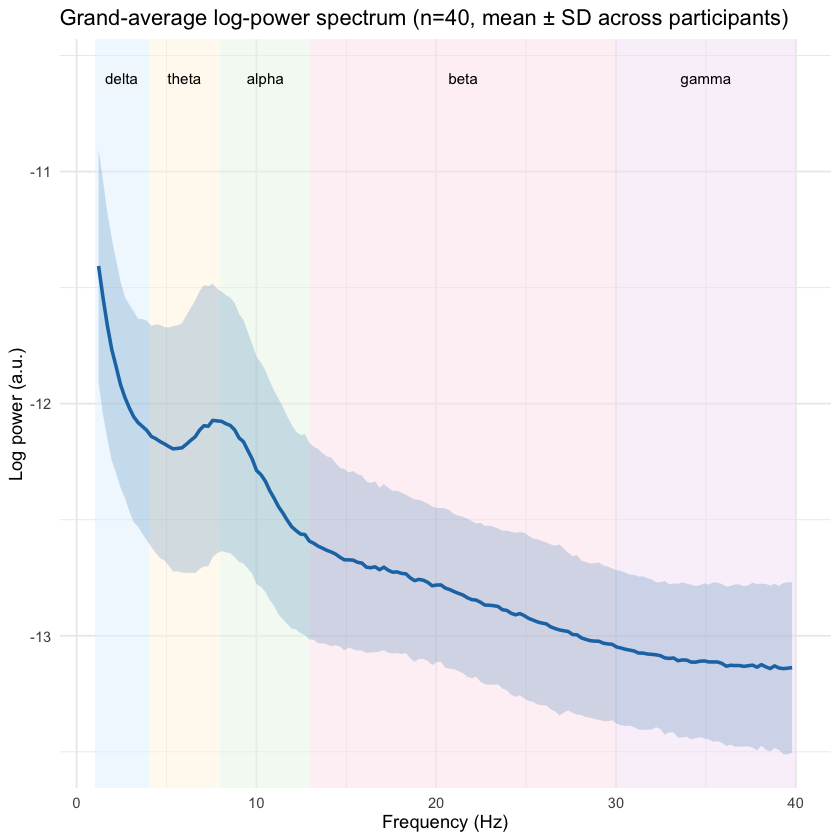

In [6]:
bands <- tribble(
  ~label,  ~lo, ~hi, ~color,
  "delta",   1,   4, "#e3f2fd",
  "theta",   4,   8, "#fff3e0",
  "alpha",   8,  13, "#e8f5e9",
  "beta",   13,  30, "#fce4ec",
  "gamma",  30,  40, "#f3e5f5"
)

spectrum <- tibble(
  freq = freqs,
  avg  = apply(psd_log, 3, mean),                    # grand average
  sd   = apply(apply(psd_log, c(1, 3), mean), 2, sd)  # SD across participants
)

fig_grandavg <- ggplot() +
  geom_rect(data = bands, aes(xmin = lo, xmax = hi, ymin = -Inf, ymax = Inf, fill = label),
            alpha = 0.5) +
  scale_fill_manual(values = set_names(bands$color, bands$label), guide = "none") +
  geom_ribbon(data = spectrum, aes(freq, ymin = avg - sd, ymax = avg + sd), alpha = 0.2, fill = "#1f77b4") +
  geom_line(data = spectrum, aes(freq, avg), color = "#1f77b4", linewidth = 1) +
  geom_text(data = bands, aes(x = (lo + hi) / 2, y = max(spectrum$avg + spectrum$sd) * 0.97, label = label),
            vjust = 1, size = 3.2) +
  labs(x = "Frequency (Hz)", y = "Log power (a.u.)",
       title = str_glue("Grand-average log-power spectrum (n={n_subj}, mean ± SD across participants)"))
fig_grandavg

# Flag participants whose spectrum looks implausible (flat, or extreme overall level)
tibble(subject_id = subject_ids,
       level  = apply(psd_log, 1, mean),
       spread = apply(psd_log, 1, sd)) %>%
  mutate(flagged = abs(level - mean(level)) > 3 * sd(level) | spread < 1e-6) %>%
  summarise(mean_level = mean(level), min_level = min(level), max_level = max(level),
            n_flagged = sum(flagged))

> **What do we see in the plot?**
>
> A real EEG power spectrum is not flat: power is highest at low
> frequencies and decays roughly as 1/frequency (the "1/f" background),
> often with a small bump around 8–13 Hz (the alpha rhythm). A flat line,
> a spectrum with no decay, or a sharp spike at a single frequency (line
> noise, typically 50 or 60 Hz) would be a data-quality warning sign.

### 1.4 Log-power distribution check

The PSD array is already log-transformed (log-power is approximately
normally distributed, whereas raw spectral power is strongly right-
skewed — the same reason we log-transformed nothing extra here, unlike a
raw-power pipeline would need to). With ~32,000 channel x frequency
points, checking each one individually is neither possible nor useful;
instead we check a handful of representative points.

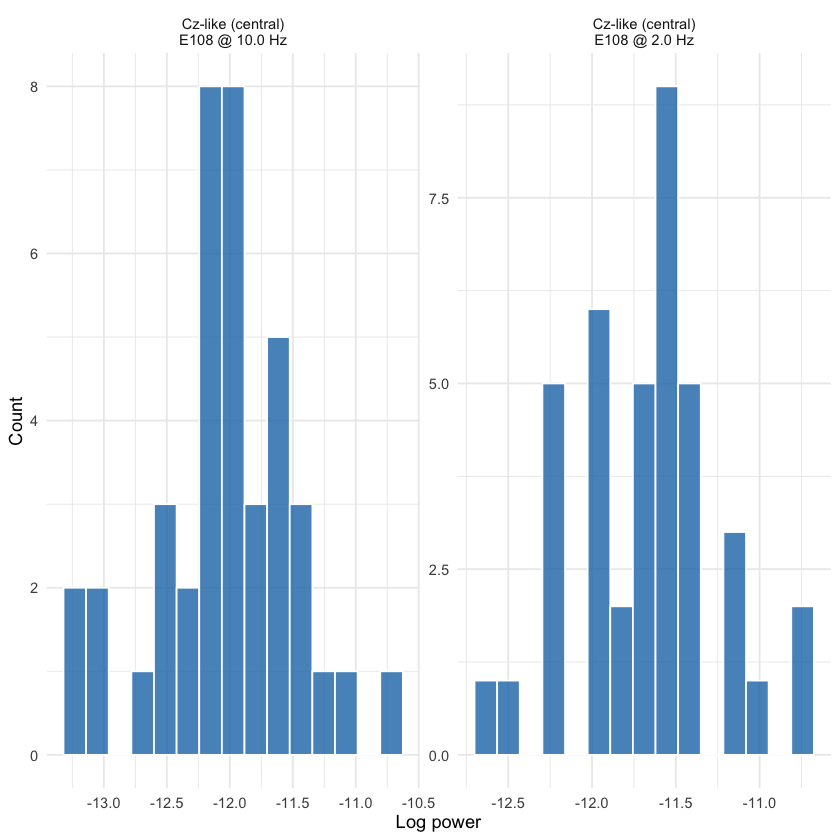

In [7]:
ci_mid   <- n_ch %/% 2
fi_delta <- which.min(abs(freqs - 2))
fi_alpha <- which.min(abs(freqs - 10))

point_label <- function(fi) str_c("Cz-like (central)\n", ch_names[ci_mid], " @ ", fmt(freqs[fi]), " Hz")

spot_check <- bind_rows(
  tibble(value = psd_log[, ci_mid, fi_delta], label = point_label(fi_delta)),
  tibble(value = psd_log[, ci_mid, fi_alpha], label = point_label(fi_alpha))
)

fig_dist <- ggplot(spot_check, aes(value)) +
  geom_histogram(bins = 15, fill = "#1f77b4", alpha = 0.8, color = "white") +
  facet_wrap(~label, scales = "free") +
  labs(x = "Log power", y = "Count")
fig_dist

> **What do we see in the plot?**
>
> Both histograms are roughly bell-shaped and symmetric, not the
> strongly right-skewed shape raw (non-log) power would show — exactly
> the pattern that justifies working with log-power. The two points
> shown (a low and a high frequency, same central channel) are just a
> spot check; with ~32,000 channel x frequency points we can't inspect
> every one, but nothing here suggests the log transform failed to do
> its job.

### 1.5 Covariate strategy

Age and CRIq are covariates, as in Case Study 1. We use **partial
correlation**: correlate log-power with MoCA after removing the linear
effect of age and CRIq from both variables. This is simpler to explain
than a two-step residualisation and gives the same result.

### 1.6 Final check

In [8]:
cli_bullets(c(
  "*" = "Final N: {n_subj}",
  "*" = "EEG array: {n_subj} x {n_ch} x {n_freq}",
  "*" = "Covariates: age, criq",
  "*" = "Outcome: moca (mean = {fmt(mean(npsy$moca), 2)}, SD = {fmt(sd(npsy$moca), 2)})"
))

• Final N: 40



• EEG array: 40 x 204 x 159



• Covariates: age, criq



• Outcome: moca (mean = 21.73, SD = 6.00)



---
## 2. Analysis

### 2.1 Descriptive statistics

In [9]:
desc_vars <- c("age", "sex", "criq", "moca")

table1 <- npsy %>%
  select(all_of(desc_vars)) %>%
  pivot_longer(everything(), names_to = "Variable") %>%
  drop_na(value) %>%
  mutate(Variable = factor(Variable, levels = desc_vars)) %>%
  group_by(Variable) %>%
  summarise(
    n     = n(),
    Value = str_c(fmt(mean(value), 2), " ± ", fmt(sd(value), 2)),
    Range = str_c("[", fmt(min(value), 2), ", ", fmt(max(value), 2), "]")
  ) %>%
  mutate(Variable = as.character(Variable))
table1

Variable,n,Value,Range
<chr>,<int>,<chr>,<chr>
age,40,65.30 ± 6.63,"[49.00, 82.00]"
sex,40,0.50 ± 0.51,"[0.00, 1.00]"
criq,40,96.10 ± 11.15,"[74.00, 119.00]"
moca,40,21.73 ± 6.00,"[8.00, 30.00]"


### 2.2 Baseline — a Case-Study-1-style model

Before analysing the whole spectrum, we fit the kind of model Case Study
1 would use: a single, a-priori ERP feature (P300 amplitude) as a
predictor of MoCA. This is deliberately naive here — P300 and resting-
state PSD are conceptually different recordings (task-based vs.
resting), so this model **cannot** detect the whole-scalp resting-state
association we are looking for. It exists only to make the contrast
concrete: a model that commits in advance to one feature can only find
an association if it happens to live there.

In [10]:
df_baseline <- inner_join(npsy, erp, by = "subject_id")
mod_baseline <- glm(moca ~ p300_amp + age + criq, data = df_baseline, family = gaussian())
summary(mod_baseline)


Call:
glm(formula = moca ~ p300_amp + age + criq, family = gaussian(), 
    data = df_baseline)

Coefficients:
            Estimate Std. Error t value Pr(>|t|)  
(Intercept) 31.66977   14.66843   2.159   0.0376 *
p300_amp    -0.33297    0.57103  -0.583   0.5635  
age         -0.20066    0.14613  -1.373   0.1782  
criq         0.07559    0.08953   0.844   0.4041  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for gaussian family taken to be 35.48726)

    Null deviance: 1406.0  on 39  degrees of freedom
Residual deviance: 1277.5  on 36  degrees of freedom
AIC: 262.07

Number of Fisher Scoring iterations: 2


### 2.3 Mass-univariate partial correlation

We now use the real, full-resolution spectrum. At **every** channel x
frequency point, we compute the partial correlation between log-power
and MoCA, controlling for age and CRIq, and convert it to a t-statistic.
This produces one map of 204 x 159 test statistics.

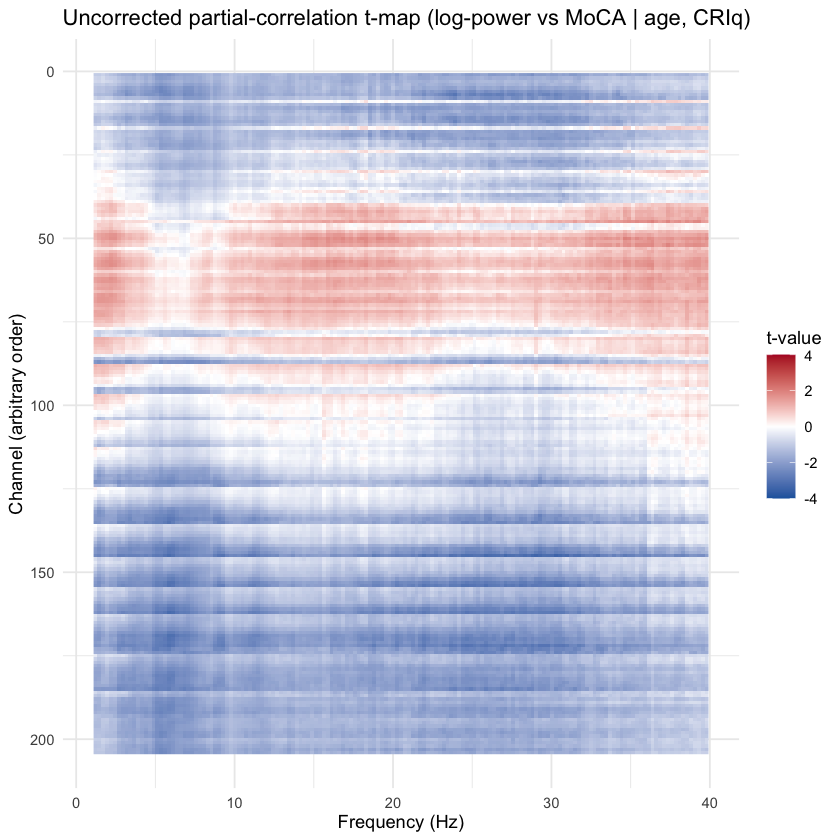

In [11]:
covariates <- npsy %>% select(age, criq)
moca <- npsy$moca

t_map <- flat_to_map(partial_corr_tmap(psd_log, moca, covariates), n_ch, n_freq)  # [channels x freqs]

tmap_df <- expand_grid(ch_i = seq_len(n_ch), freq_i = seq_len(n_freq)) %>%
  mutate(freq = freqs[freq_i], t = t_map[cbind(ch_i, freq_i)])

fig_tmap <- ggplot(tmap_df, aes(freq, ch_i, fill = t)) +
  geom_raster() +
  scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b", midpoint = 0,
                       limits = c(-4, 4), oob = scales::squish, name = "t-value") +
  scale_y_reverse() +
  labs(x = "Frequency (Hz)", y = "Channel (arbitrary order)",
       title = "Uncorrected partial-correlation t-map (log-power vs MoCA | age, CRIq)")
fig_tmap

In [12]:
# Want to see how it works? Printing a function shows its source code.
print(partial_corr_tmap)

function(log_power, y, covariates) {
  n <- length(y)
  Z <- cbind(1, as.matrix(covariates))
  Z_pinv <- MASS::ginv(Z)
  resid_y <- y - Z %*% (Z_pinv %*% y)
  Y <- matrix(aperm(log_power, c(1, 3, 2)), nrow = n)
  resid_power <- Y - Z %*% (Z_pinv %*% Y)
  num <- as.vector(t(resid_y) %*% resid_power)
  den <- sqrt(sum(resid_y^2)) * sqrt(colSums(resid_power^2))
  r <- pmax(pmin(num / den, 0.999999), -0.999999)
  df <- n - ncol(Z) - 1   # n - intercept - covariates - y
  r * sqrt(df / (1 - r^2))
}
<bytecode: 0x16ee48c78>


> **What do we see in the plot?**
>
> Each pixel is one channel x frequency combination; colour is the
> t-value of its partial correlation with MoCA (red = positive, blue =
> negative). **This map on its own is not trustworthy**: with ~32,000
> simultaneous tests, a conventional p<0.05 threshold would flag over
> 1,600 points purely by chance. We need a correction that accounts for
> how many tests we ran *and* respects the fact that neighbouring
> points are not independent — which is exactly what cluster-based
> permutation testing does (next section).

### 2.4 Cluster-based permutation test

**The idea, in plain terms**: instead of correcting each point in
isolation, we group *neighbouring* suprathreshold points into clusters
(a point is a neighbour of another if they are adjacent channels at the
same frequency, or the same channel at adjacent frequency bins), sum the
t-values within each cluster, and ask: *if MoCA were randomly shuffled
across participants (so any true association is destroyed), how often
would a cluster this large arise purely by chance?* We estimate that by
actually shuffling MoCA thousands of times and recomputing the largest
cluster each time — this is the permutation *null distribution*. A
cluster's p-value is simply the fraction of shuffles that produced a
cluster at least as extreme as the one we observed.

Spatial adjacency comes from the real 3D positions of the EGI-256
montage, pre-exported by `compute_montage_assets.ipynb`; spectral
adjacency links consecutive frequency bins (Maris & Oostenveld, 2007).

We run **two**, pre-planned analyses:

- **Primary** — the whole spectrum (1–40 Hz), every channel, no a priori
  restriction. This is the test the paper's framing is built around:
  it can find an effect anywhere, at the cost of a large multiple-
  comparisons penalty.
- **Secondary / confirmatory** — restricted a priori to the region the
  clinical literature actually predicts (right hemisphere, delta/theta,
  1–8 Hz). Restricting the search space *before* looking at the data is
  standard practice when there is a specific hypothesis, and it recovers
  power the whole-spectrum test gives up. We report both, rather than
  only the one that "worked", precisely to avoid the circular reasoning
  Case Study 1 warned about (Section 2.3 there): the secondary result is
  only informative because it was planned, not because we went looking
  for whichever restriction happened to be significant.

> ⚠️ **Caution** - the cluster-based permutation functions used here
> (`cluster_permutation_test()` and its helpers, in
> [`R/cluster_permutation.R`](https://github.com/SanCamilloIRCCS-OndaLab/tutorial_EEG-NPSY/blob/main/r/case2/code/R/cluster_permutation.R)) are a minimal,
> didactic implementation, written only so this tutorial runs in R without
> extra dependencies. They are **not extensively tested** and are **not** a
> validated or published implementation of the method. For real analyses
> use established, peer-reviewed tools - MNE-Python (`mne.stats`),
> FieldTrip, or the R package `permuco`.

In [13]:
# Channel positions and neighbouring pairs, pre-exported from the real montage
ch_pos_3d <- read_csv(file.path(PSD_DIR, "montage_ch_pos_3d.csv"), show_col_types = FALSE)
stopifnot(all(ch_pos_3d$channel == ch_names))
edges <- read_csv(file.path(PSD_DIR, "montage_adjacency_edges.csv"), show_col_types = FALSE)

# How far right each channel sits: ~0 = far left, ~1 = far right (+x = right, head frame)
xs <- ch_pos_3d$x
w_right <- 0.5 * (1 + tanh(xs / (max(abs(xs)) / 2)))
delta_theta <- freqs >= 1 & freqs <= 8

spatial_adjacency <- adjacency_from_edges(edges, ch_names)

T_THRESH <- 2.028   # ~two-tailed p<0.05, df = n-4 = 36
N_PERM <- 2000

In [14]:
# Want to see how it works? Printing a function shows its source code.
print(adjacency_from_edges)

function(edges, ch_names) {
  ch_index <- set_names(seq_along(ch_names), ch_names)
  i1 <- ch_index[edges$ch1]
  i2 <- ch_index[edges$ch2]
  n <- length(ch_names)
  sparseMatrix(i = c(i1, i2), j = c(i2, i1), x = 1, dims = c(n, n))
}


In [15]:
combined_adjacency <- combine_adjacency(spatial_adjacency, n_freq)
primary <- cluster_permutation_test(psd_log, moca, covariates, combined_adjacency,
                                    t_thresh = T_THRESH, n_perm = N_PERM, seed = 1)
primary_clusters <- primary$clusters
t_obs_primary <- primary$t_obs

# Primary (whole spectrum, no a priori restriction): the three largest clusters
clusters_to_table(primary_clusters, freqs, w_right, seq_len(n_ch), "Primary (whole spectrum)") %>%
  head(3)

Analysis,Cluster rank,Cluster mass,N points,Freq min (Hz),Freq max (Hz),Mean w_right,p_cluster
<chr>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Primary (whole spectrum),1,-4059.66754,1719,16.113281,39.55078,0.8620513,0.2030
Primary (whole spectrum),2,-3343.06440,1442,1.220703,14.16016,0.8841820,0.2310
Primary (whole spectrum),3,-18.61123,9,14.648438,15.38086,0.9788429,0.7935


In [16]:
# Want to see how it works? Printing a function shows its source code.
print(combine_adjacency)
print(cluster_permutation_test)
print(find_clusters)
print(clusters_to_table)

function(spatial_adj, n_freq) {
  n_ch <- nrow(spatial_adj)
  kronecker(spatial_adj, Diagonal(n_freq)) + kronecker(Diagonal(n_ch), freq_chain_adjacency(n_freq))
}


function(log_power, y, covariates, adjacency,
                                     t_thresh = 2.028, n_perm = 2000, seed = 1) {
  n_ch <- dim(log_power)[2]
  n_freq <- dim(log_power)[3]
  set.seed(seed)
  t_obs <- partial_corr_tmap(log_power, y, covariates)
  obs_clusters <- find_clusters(t_obs, t_thresh, adjacency)
  obs_clusters <- obs_clusters[order(-abs(sapply(obs_clusters, function(c) c$mass)))]
  n <- length(y)
  null_max <- numeric(n_perm)
  for (i in seq_len(n_perm)) {
    shuffled <- sample(n)
    t_perm <- partial_corr_tmap(log_power, y[shuffled], covariates)
    cl <- find_clusters(t_perm, t_thresh, adjacency)
    null_max[i] <- if (length(cl) == 0) 0 else max(abs(sapply(cl, function(c) c$mass)))
  }
  results <- list()
  top <- obs_clusters[seq_len(min(5, length(obs_clusters)))]
  for (c in top) {
    p <- mean(null_max >= abs(c$mass))
    results[[length(results) + 1]] <- list(members = c$members, mass = c$mass, p_cluster = p)
  }
  list(clusters = results, t_obs = flat_to

function(t_flat, t_thresh, adjacency) {
  clusters <- list()
  for (sign in c(1, -1)) {
    supra <- which((t_flat * sign) > t_thresh)
    if (length(supra) == 0) next
    # build the suprathreshold subgraph straight from the sparse
    # adjacency's own (i, j) triplets, without ever densifying it
    sub_adj <- as(adjacency[supra, supra], "TsparseMatrix")
    el <- cbind(sub_adj@i + 1L, sub_adj@j + 1L)
    el <- el[el[, 1] < el[, 2], , drop = FALSE]
    g <- igraph::make_empty_graph(n = length(supra), directed = FALSE)
    if (nrow(el) > 0) g <- igraph::add_edges(g, as.vector(t(el)))
    comp <- igraph::components(g)
    for (k in seq_len(comp$no)) {
      members <- supra[comp$membership == k]
      clusters[[length(clusters) + 1]] <- list(members = members, mass = sum(t_flat[members]))
    }
  }
  clusters
}
<bytecode: 0x10dfc9760>


function(clusters, freqs, w_right, ch_index_map, label) {
  clusters %>%
    imap(function(cl, rank) {
      idx <- arrayInd(cl$members, .dim = c(length(freqs), length(ch_index_map)))
      fi <- idx[, 1]
      ci <- idx[, 2]
      tibble(
        Analysis        = label,
        `Cluster rank`  = rank,
        `Cluster mass`  = cl$mass,
        `N points`      = length(cl$members),
        `Freq min (Hz)` = min(freqs[fi]),
        `Freq max (Hz)` = max(freqs[fi]),
        `Mean w_right`  = mean(w_right[ch_index_map[unique(ci)]]),
        p_cluster       = cl$p_cluster
      )
    }) %>%
    list_rbind()
}
<bytecode: 0x126cb9af8>


In [17]:
right_idx <- which(w_right > 0.5)
freq_idx  <- which(delta_theta)
n_ch_roi <- length(right_idx); n_freq_roi <- length(freq_idx)
roi_spatial_adjacency <- spatial_adjacency[right_idx, right_idx]
roi_adjacency <- combine_adjacency(roi_spatial_adjacency, n_freq_roi)

secondary <- cluster_permutation_test(psd_log[, right_idx, freq_idx], moca, covariates, roi_adjacency,
                                      t_thresh = T_THRESH, n_perm = N_PERM, seed = 1)
secondary_clusters <- secondary$clusters

# Secondary / confirmatory (right hemisphere x 1-8 Hz, pre-registered ROI)
clusters_to_table(secondary_clusters, freqs[freq_idx], w_right, right_idx,
                  "Secondary (right hemisphere x 1-8 Hz)") %>%
  head(3)

Analysis,Cluster rank,Cluster mass,N points,Freq min (Hz),Freq max (Hz),Mean w_right,p_cluster
<chr>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Secondary (right hemisphere x 1-8 Hz),1,-2432.35,1038,1.220703,7.8125,0.908603,0.041


**Reading the result honestly**: the primary, whole-spectrum test is
not expected to survive correction at n=40 — this mirrors the paper's own
caveat that cluster-based permutation is relatively underpowered at this
sample size, so only fairly marked associations are likely to survive.
The secondary, pre-registered test recovers a significant cluster,
consistent with the hypothesised right-hemisphere, low-frequency
pattern.

### 2.5 Where is the effect? (topography of the significant cluster)

For the significant cluster from the secondary analysis, we plot a
topographic map of the (partial-correlation) t-values, averaged over the
cluster's frequency range, with the cluster's channels highlighted.

The scalp outline and 2D electrode positions below are the same ones
`mne.viz.plot_topomap` uses for this montage, pre-exported (so this
never has to invent its own projection); the colour surface
itself is a simple, local loess smoother over the real channel
values. Rather than adding a full EEG package for a single plot, we use a
small helper, `topomap_plot()`, from our `R/` folder (the `eegUtils`
package offers a full-featured alternative).

In [18]:
outline <- read_csv(file.path(PSD_DIR, "montage_outline.csv"), show_col_types = FALSE)
montage <- list(
  pos_2d      = read_csv(file.path(PSD_DIR, "montage_ch_pos_2d.csv"), show_col_types = FALSE),
  outline     = outline,
  clip_radius = outline %>% filter(part == "clip_radius") %>% pull(x) %>% first()
)
stopifnot(all(montage$pos_2d$channel == ch_names))

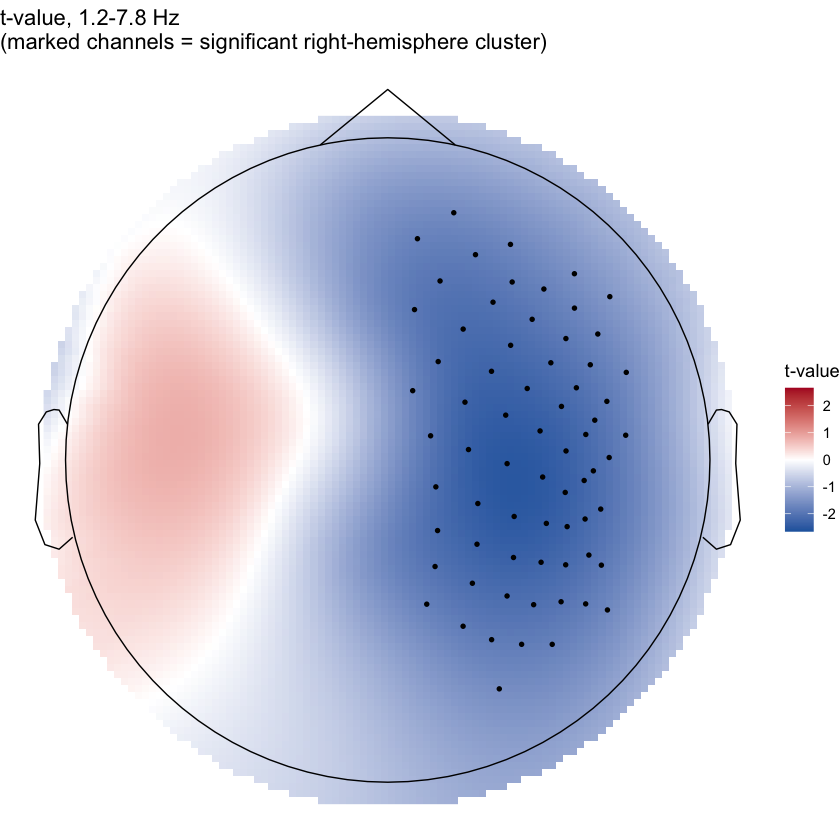

In [19]:
best <- secondary_clusters[[1]]
idx <- arrayInd(best$members, .dim = c(n_freq_roi, n_ch_roi))
fi_cluster <- idx[, 1]; ci_cluster <- idx[, 2]
cluster_ch_global <- right_idx[unique(ci_cluster)]   # map back to the full 204-channel indexing
cluster_freq_range <- range(freqs[freq_idx][fi_cluster])

# Average t-value per channel over the cluster's frequency range, using the
# PRIMARY (whole-head, all real channels) map - so both hemispheres show
# real data; only the significant channels (right hemisphere) are marked.
freq_mask_cluster <- between(freqs, cluster_freq_range[1], cluster_freq_range[2])
t_avg_full <- rowMeans(t_obs_primary[, freq_mask_cluster, drop = FALSE])

fig_topo <- topomap_plot(
  t_avg_full, montage,
  mask = seq_len(n_ch) %in% cluster_ch_global,
  title = str_glue("t-value, {fmt(cluster_freq_range[1])}-{fmt(cluster_freq_range[2])} Hz\n",
                   "(marked channels = significant right-hemisphere cluster)")
)
fig_topo

In [20]:
# Want to see how it works? Printing a function shows its source code.
print(topomap_plot)

function(values, montage, mask = NULL, title = "", vlim = NULL, grid_n = 100) {
  r_max <- montage$clip_radius
  grid <- expand_grid(x2d = seq(-r_max, r_max, length.out = grid_n),
                      y2d = seq(-r_max, r_max, length.out = grid_n))
  fit <- loess(value ~ x2d * y2d,
               data = tibble(x2d = montage$pos_2d$x2d, y2d = montage$pos_2d$y2d, value = values),
               degree = 2, span = 0.35, control = loess.control(surface = "direct"))
  grid <- grid %>%
    mutate(pred = as.vector(predict(fit, newdata = grid))) %>%
    filter(sqrt(x2d^2 + y2d^2) <= r_max)   # keep only the inside of the head

  if (is.null(vlim)) {
    lim <- max(abs(values), na.rm = TRUE)
    vlim <- c(-lim, lim)
  }

  head_outline <- montage$outline %>%
    filter(part %in% c("head", "nose", "ear_left", "ear_right"))

  p <- ggplot() +
    geom_raster(data = grid, aes(x2d, y2d, fill = pred)) +
    scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b", midpoint = 0,
        

> **What do we see in the plot?**
>
> A clear right-lateralised, negative (blue) region over the
> posterior-right scalp, with the significant cluster's channels
> marked as black dots inside it — exactly the hemisphere and sign
> (lower MoCA, higher delta/theta power) the clinical hypothesis
> predicted. The left hemisphere, shown with real data too, is
> comparatively flat: the effect isn't a generic "more power is
> worse" pattern, it's localised to the predicted side.

### 2.6 Illustrative check: PSD by MoCA level

Purely for illustration (not a separate statistical test), we split
participants by a median MoCA split and plot the average spectrum at the
cluster's channels for each group.

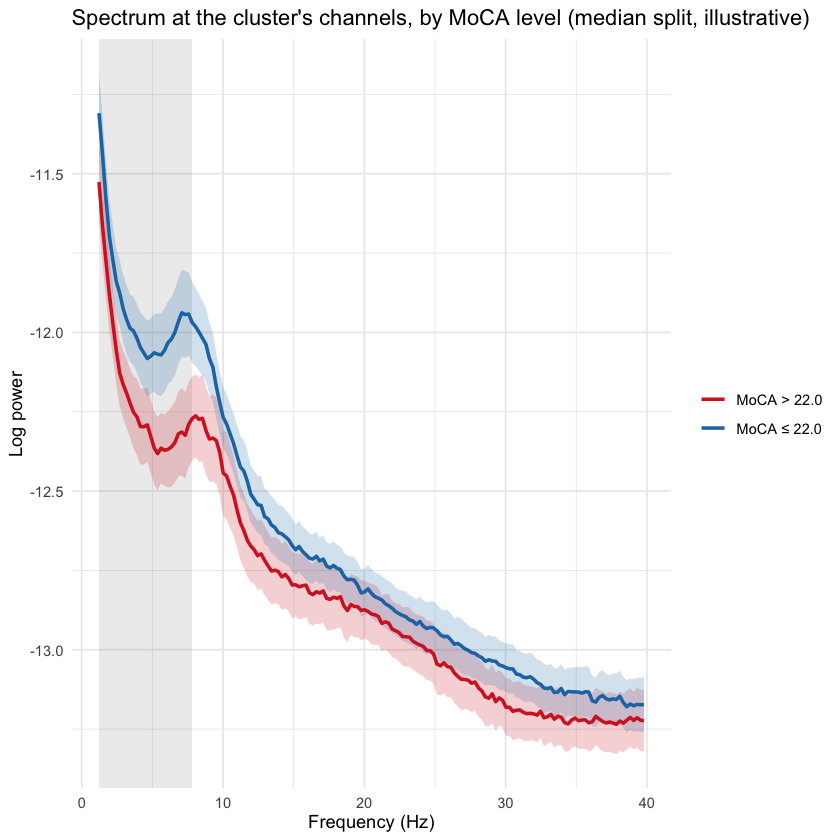

In [21]:
median_moca <- median(moca)

# Spectrum averaged over the cluster's channels, per participant, across the
# FULL spectrum (not just the ROI's 1-8 Hz subset) - so the plot shows what
# happens outside the tested range too
psd_cluster_ch <- apply(psd_log[, cluster_ch_global, , drop = FALSE], c(1, 3), mean)  # [subjects x freqs]

group_df <- tibble(
  subject = rep(seq_len(n_subj), times = n_freq),
  freq    = rep(freqs, each = n_subj),
  power   = as.vector(psd_cluster_ch)
) %>%
  mutate(label = if_else(moca[subject] <= median_moca,
                         str_c("MoCA \u2264 ", fmt(median_moca)),
                         str_c("MoCA > ", fmt(median_moca)))) %>%
  group_by(label, freq) %>%
  summarise(mean = mean(power), sem = sd(power) / sqrt(n()), .groups = "drop")

fig_bygroup <- ggplot(group_df, aes(freq, mean, color = label, fill = label)) +
  annotate("rect", xmin = cluster_freq_range[1], xmax = cluster_freq_range[2], ymin = -Inf, ymax = Inf,
           alpha = 0.15, fill = "gray50") +
  geom_ribbon(aes(ymin = mean - sem, ymax = mean + sem), alpha = 0.2, color = NA) +
  geom_line(linewidth = 1) +
  scale_color_manual(values = c("#d62728", "#1f77b4"), name = NULL) +
  scale_fill_manual(values = c("#d62728", "#1f77b4"), guide = "none") +
  labs(x = "Frequency (Hz)", y = "Log power",
       title = "Spectrum at the cluster's channels, by MoCA level (median split, illustrative)")
fig_bygroup

> **What do we see in the plot?**
>
> The lower-MoCA group (red) sits above the higher-MoCA group (blue)
> across most of the spectrum, and the gap is most visible within the
> shaded significant-cluster range (1–8 Hz) — consistent with the
> cluster test's finding of more low-frequency power in participants
> with poorer cognition. This is a median split shown only for
> intuition, not a second statistical test: the real evidence is the
> cluster-permutation result above.

### 2.7 Exploratory: which canonical band drives the effect?

The secondary analysis above pools delta and theta (1–8 Hz) into a single
test. It is natural to ask whether the effect is really carried by both,
or mainly by one of them — and whether it is genuinely absent in
alpha/beta/gamma, as the clinical hypothesis would predict.

**This is an exploratory, supplementary analysis, not a substitute for
the pre-registered primary/secondary tests above.** We repeat the same
cluster-permutation procedure (same right-hemisphere ROI, same
threshold) separately for each of the five canonical bands. Because this
means testing **five** hypotheses instead of one, we apply a Bonferroni
correction across bands (multiply each band's p-value by 5, capped at 1)
— exactly the kind of correction Case Study 1 discussed for multiple
outcomes, applied here to multiple frequency bands instead.

In [22]:
CANONICAL_BANDS <- list(delta = c(1, 4), theta = c(4, 8), alpha = c(8, 13),
                        beta = c(13, 30), gamma = c(30, 40))

band_results <- imap(CANONICAL_BANDS, function(limits, band) {
  band_freq_idx <- which(freqs >= limits[1] & freqs < limits[2])
  band_adjacency <- combine_adjacency(roi_spatial_adjacency, length(band_freq_idx))
  res <- cluster_permutation_test(psd_log[, right_idx, band_freq_idx], moca, covariates, band_adjacency,
                                  t_thresh = T_THRESH, n_perm = N_PERM, seed = 1)
  # the largest cluster (or an empty one, if nothing crossed the threshold)
  top <- if (length(res$clusters) > 0) res$clusters[[1]] else list(mass = 0, members = integer(0), p_cluster = 1)
  list(freq_range = limits, freq_idx = band_freq_idx, top = top,
       p_bonferroni = min(top$p_cluster * length(CANONICAL_BANDS), 1))
})

table4_bands <- band_results %>%
  imap(function(res, band) {
    tibble(
      Band                   = band,
      `Freq min (Hz)`        = res$freq_range[1],
      `Freq max (Hz)`        = res$freq_range[2],
      `Cluster mass`         = res$top$mass,
      `N points`             = length(res$top$members),
      p_raw                  = res$top$p_cluster,
      `p_bonferroni (x5)`    = res$p_bonferroni,
      `Significant (p<0.05)` = res$p_bonferroni < 0.05
    )
  }) %>%
  list_rbind()
table4_bands

Band,Freq min (Hz),Freq max (Hz),Cluster mass,N points,p_raw,p_bonferroni (x5),Significant (p<0.05)
<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<lgl>
delta,1,4,-544.6824,242,0.0755,0.3775,FALSE
theta,4,8,-1887.6678,796,0.0290,0.1450,FALSE
alpha,8,13,-761.1933,335,0.0920,0.4600,FALSE
beta,13,30,-3002.9947,1263,0.0805,0.4025,FALSE
gamma,30,40,-877.7029,376,0.1400,0.7000,FALSE


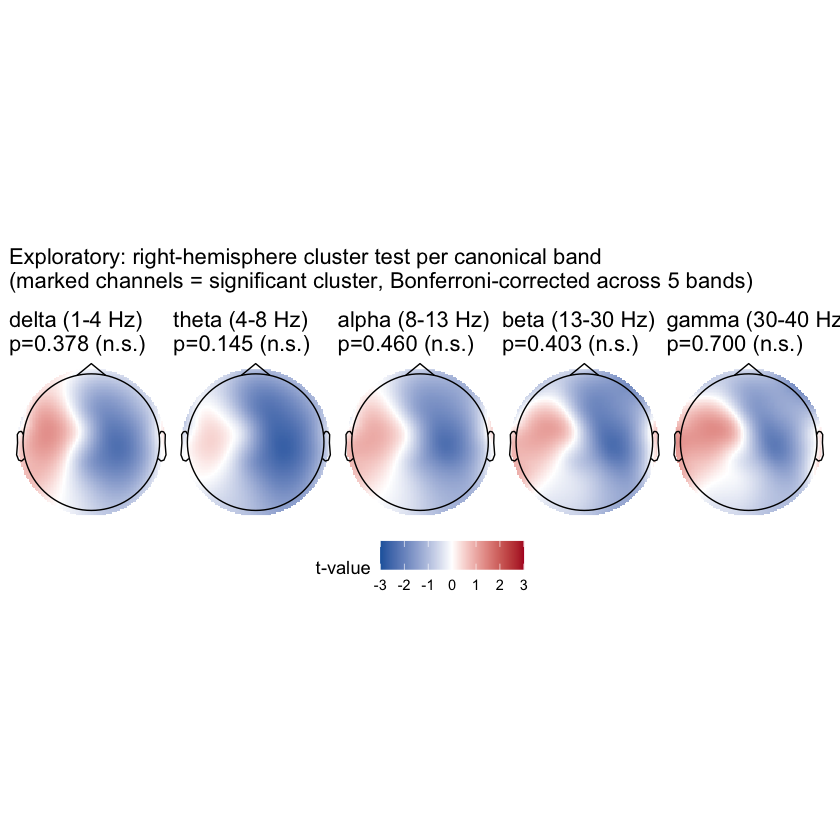

In [23]:
band_panels <- imap(band_results, function(res, band) {
  in_band <- freqs >= res$freq_range[1] & freqs < res$freq_range[2]
  t_avg_band <- rowMeans(t_obs_primary[, in_band, drop = FALSE])

  significant <- res$p_bonferroni < 0.05
  mask <- rep(FALSE, n_ch)
  if (significant) {
    idx <- arrayInd(res$top$members, .dim = c(length(res$freq_idx), n_ch_roi))
    mask[right_idx[unique(idx[, 2])]] <- TRUE
  }

  topomap_plot(
    t_avg_band, montage, mask = mask, vlim = c(-3, 3),
    title = str_glue("{band} ({res$freq_range[1]}-{res$freq_range[2]} Hz)\n",
                     "p={fmt(res$p_bonferroni, 3)} ({if (significant) 'significant' else 'n.s.'})")
  )
})

fig_bands <- wrap_plots(band_panels, nrow = 1) +
  plot_layout(guides = "collect") +
  plot_annotation(title = "Exploratory: right-hemisphere cluster test per canonical band\n(marked channels = significant cluster, Bonferroni-corrected across 5 bands)") &
  theme(legend.position = "bottom")
fig_bands

> **What do we see in the plots?**
>
> Each panel is one canonical band, coloured by the same t-value scale;
> a panel's channels would be marked if that band's cluster survived
> correction for having tested five bands. This is a noticeably messier
> picture than a clean "low frequencies yes, high frequencies no" split:
> **none of the five individual bands survives Bonferroni correction**
> (theta comes closest, at a raw p≈0.03 that is no longer below 0.05
> once multiplied by 5), even though several bands show the same
> right-lateralised, negative direction as the pre-registered secondary
> test above.
>
> This is a more informative result than a clean split would have been,
> for two reasons. First, it is a direct, concrete illustration of why
> multiple-comparison correction matters: taken on its own, theta's raw
> p-value would look like a finding — it only stops looking like one once
> we account for having tested five bands instead of pre-committing to
> one. Second, it shows why the secondary analysis pooled delta and theta
> together rather than testing them separately: combining adjacent
> frequency bins into one wider band gives the cluster more points to
> draw statistical mass from, which is exactly what recovers the
> significant result there. Splitting the spectrum into ever-narrower
> slices trades away the power that made the pooled test work in the
> first place — the same lesson Case Study 1 taught about predictors,
> now shown for frequency bands.

---
## 3. Export

Same philosophy as Case Study 1: figures as PNG, tables as both CSV and
a single Excel workbook.

In [24]:
figures <- list(
  "A_grand_average_psd.png"       = fig_grandavg,
  "B_log_power_distributions.png" = fig_dist,
  "C_uncorrected_tmap.png"        = fig_tmap,
  "D_cluster_topography.png"      = fig_topo,
  "E_psd_by_moca_level.png"       = fig_bygroup,
  "F_band_topographies.png"       = fig_bands
)

iwalk(figures, function(plot, filename) {
  path <- file.path(FIGS, filename)
  ggsave(path, plot, width = 9, height = 5, dpi = 150, bg = "white")
  cli_alert_success("Saved {.file {path}}")
})

✔ Saved ../outputs/figures/A_grand_average_psd.png



✔ Saved ../outputs/figures/B_log_power_distributions.png



✔ Saved ../outputs/figures/C_uncorrected_tmap.png



✔ Saved ../outputs/figures/D_cluster_topography.png



✔ Saved ../outputs/figures/E_psd_by_moca_level.png



✔ Saved ../outputs/figures/F_band_topographies.png



In [25]:
table2_clusters <- bind_rows(
  clusters_to_table(primary_clusters, freqs, w_right, seq_len(n_ch), "Primary (whole spectrum)"),
  clusters_to_table(secondary_clusters, freqs[freq_idx], w_right, right_idx, "Secondary (right hemisphere x 1-8 Hz)")
)
table2_clusters

Analysis,Cluster rank,Cluster mass,N points,Freq min (Hz),Freq max (Hz),Mean w_right,p_cluster
<chr>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Primary (whole spectrum),1,-4059.667542,1719,16.113281,39.55078,0.8620513,0.2030
Primary (whole spectrum),2,-3343.064403,1442,1.220703,14.16016,0.8841820,0.2310
Primary (whole spectrum),3,-18.611234,9,14.648438,15.38086,0.9788429,0.7935
Primary (whole spectrum),4,-12.841951,6,33.935547,34.42383,0.5706174,0.8215
Primary (whole spectrum),5,-8.624364,4,28.076172,28.80859,0.9693068,0.8415
Secondary (right hemisphere x 1-8 Hz),1,-2432.350145,1038,1.220703,7.81250,0.9086030,0.0410


In [26]:
table3_baseline <- tidy(mod_baseline) %>%
  transmute(
    Predictor              = term,
    Estimate               = estimate,
    `Std. Error`           = std.error,
    `p-value`              = p.value,
    `Significant (p<0.05)` = p.value < 0.05
  )
table3_baseline

Predictor,Estimate,Std. Error,p-value,Significant (p<0.05)
<chr>,<dbl>,<dbl>,<dbl>,<lgl>
(Intercept),31.66976987,14.66843095,0.03758746,TRUE
p300_amp,-0.33296649,0.57102903,0.56346183,FALSE
age,-0.20065946,0.14612654,0.17818628,FALSE
criq,0.07558692,0.08952767,0.40408566,FALSE


In [27]:
tables <- list(
  "table1_descriptives.csv"   = table1,
  "table2_clusters.csv"       = table2_clusters,
  "table3_baseline_model.csv" = table3_baseline,
  "table4_band_breakdown.csv" = table4_bands
)

iwalk(tables, function(table, filename) {
  path <- file.path(RESULTS, filename)
  write_csv(table, path)
  cli_alert_success("Saved {.file {path}}")
})

# The same four tables in one Excel workbook, one sheet each
xlsx_path <- file.path(RESULTS, "CaseStudy_2_results.xlsx")
openxlsx::write.xlsx(
  list(Descriptives = table1, Clusters = table2_clusters,
       `Baseline model` = table3_baseline, `Band breakdown` = table4_bands),
  xlsx_path, overwrite = TRUE
)
cli_alert_success("Saved {.file {xlsx_path}}")

✔ Saved ../outputs/results/table1_descriptives.csv



✔ Saved ../outputs/results/table2_clusters.csv



✔ Saved ../outputs/results/table3_baseline_model.csv



✔ Saved ../outputs/results/table4_band_breakdown.csv



✔ Saved ../outputs/results/CaseStudy_2_results.xlsx



---
## 4. Strengths and limitations of this approach (Section 4.2.3)

**Strengths:**
- No a priori commitment to a specific band or region — able to recover a
  **distributed, low-frequency, right-hemisphere pattern** that no single
  ERP feature (Case Study 1) would capture (Section 2.2 above)
- Respects the real spatial and spectral dependency structure of the
  signal, unlike testing every point independently

**Limitations:**
- **Computationally heavier** than the GLM-based approach of Case Study 1
- **Statistically demanding**: with around forty participants,
  cluster-based permutation is relatively underpowered, so only fairly
  marked associations are likely to survive — the whole-spectrum
  (primary) test in Section 2.4 illustrates this directly
- A significant *secondary* result depends on having pre-registered the
  restricted region **before** looking at the data; restricting only
  after seeing what "worked" would be the same circular reasoning
  Case Study 1 warned against, just at the level of search space instead
  of predictor selection

> For a full discussion, see Section 4.2 of the companion paper, and
> Section 5.1 on general caveats (multiple comparisons, and not equating
> analytical complexity with validity).

---

*Generated for the EEG-NPSY tutorial. The analysis uses standard R
packages plus a few helper functions in the `R/` folder next to this
notebook - all of it open for inspection.*